## 09 - CIBERSORTx Reference-Matrix Sanity Check: LM22 vs. Peng Single-Cell Reference

### Aim
* Notebook 05/07's primary pipeline uses CIBERSORTx's default **LM22** signature matrix, which gives a clean lymphoid signal that independently agrees with TIMER and XDec (notebook 07). As an exploratory alternative, this notebook builds a **custom signature matrix from the Peng et al. single-cell PDAC reference** (the same reference XDec uses) via CIBERSORTx's `--single_cell TRUE` Docker mode, to see whether a reference-matched custom matrix does any better. It does not - this notebook documents why, and rules out two candidate explanations (reference cell-count cap, TPM as the bulk-mixture input unit) before landing on the most likely one (the custom signature-matrix construction itself).
* **This is a sanity/robustness check, analogous to notebook 08's raw-counts-vs-TPM check for XDec - it does not change the primary pipeline.** Notebook 05 continues to use LM22; notebook 07's cross-tool comparison continues to use the LM22-based CIBERSORTx result as primary.

### Input
* `data/deconvolution/cibersortx/mixture_TPM.txt` (notebook 05) - same TPM bulk mixture used by the primary LM22 run.
* `data/deconvolution/xdec/refs.tsv` + `ref_metadata.tsv` (notebook 04) - the Peng single-cell reference already exported for XDec, reshaped into CIBERSORTx's single-cell reference format.
* `data/deconvolution/cibersortx/CIBERSORTx_Job1_Adjusted.txt` (notebook 05, LM22, primary) and `data/deconvolution/timer_real_full/results/score_matrix.txt` (notebook 06) - for cross-tool comparison against the Peng-reference result.
* `data/deconvolution/sensitivity/full_pipeline_counts_vs_tpm_20261101_233117/` (notebook 08) - reused directly for the TPM-input-hypothesis test in Part 9.

### Output
* `data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/` - the Peng-reference CIBERSORTx run (`CIBERSORTx_Adjusted.txt`, derived signature matrix, intermediate single-cell QC files), all four axes' tertile DE + GO/KEGG tables (lymphoid/myeloid/fibroblast/enteroendocrine), and the Peng-vs-everything concordance tables/figures.

### Steps
1. Build CIBERSORTx's single-cell reference file from the Peng export and run CIBERSORTx Fractions in `--single_cell TRUE` mode (S-mode batch correction, `--fraction 0`). (Part 1)
2. Compare the resulting fractions against TIMER and XDec - cross-tool concordance, same recipe as notebook 07 Section 1. (Part 2)
3. Run the same tertile-split DE + GO/KEGG recipe as notebook 07 on all four axes CIBERSORTx-Peng can score (lymphoid, myeloid, fibroblast/CAF, enteroendocrine), comparing against XDec's and TIMER's independent results wherever available. (Parts 3-7)
4. Test whether the single-cell reference's 300-cells-per-class cap explains the failure, by rerunning with a 2.3x larger reference (700/class). (Part 8)
5. Test whether TPM (vs. raw counts) as the bulk-mixture input unit explains the failure, by cross-referencing notebook 08's existing XDec counts-vs-TPM sensitivity results, and by noting that CIBERSORTx's own LM22-vs-Peng comparison already holds the TPM input fixed and varies only the reference. (Part 9)

### Result
* **The Peng-reference run does not replicate the LM22 run's cross-tool agreement on any of the four axes tested**, and the failure pattern is a systematic cross-wiring: the "lymphoid" tertile split recovers a neuroendocrine/secretory signature, "enteroendocrine" recovers an ECM/collagen signature, "fibroblast" recovers an immune signature, and "myeloid" recovers an unrelated epithelial/digestion signature.
* **Increasing the reference cap from 300 to 700 cells/class (2.3x) does not fix it**: two of four axes (fibroblast, enteroendocrine) are essentially unchanged, and the other two (lymphoid, myeloid) just rotate to a *different* wrong signal rather than converging on the correct one. A further increase to 1500/class OOM-crashed the Docker container (7.65GB memory limit) before producing output, so it could not be tested.
* **TPM as the bulk-mixture input unit is a real but only partial factor.** XDec's own counts-vs-TPM sensitivity check (notebook 08) shows TPM genuinely destroys its lymphoid signal (74 -> 5 genes, zero overlap) but *improves* its enteroendocrine signal (58 -> 168 genes, 55 shared) and never produces one for fibroblast either way (0 genes under both units) - so TPM-input sensitivity does not generalize across axes the way CIBERSORTx-Peng's failure does. More directly: CIBERSORTx's own LM22 and Peng runs use the **identical** TPM mixture file - only the reference differs - and LM22+TPM is clean. That rules out TPM-as-input as the primary driver for CIBERSORTx specifically.

### Conclusion
* **The primary pipeline is correct to keep LM22 as CIBERSORTx's reference** (notebooks 05 and 07 are unaffected by this investigation). The most likely remaining explanation for the Peng-reference failure is the custom signature-matrix construction itself (CIBERSORTx's SVR-based gene selection against a single-cell reference with a dominant acinar/enteroendocrine compositional background and a modest cell count per class), not the reference size or the TPM input format - but this notebook demonstrates what was ruled out, not a final mechanistic proof.

## Part 1: Build and run CIBERSORTx with a Peng-reference custom signature matrix

In [1]:
import os
import shutil

import pandas as pd

if os.path.basename(os.getcwd()) == "rnaseq_download":
    os.chdir(os.path.join("..", ".."))
os.getcwd()

'/Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress'

### Step 1: build CIBERSORTx inputs (mixture file + Peng scRNA-seq reference)

In [2]:
ciber_dir = "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx"
os.makedirs(ciber_dir, exist_ok=True)

mixture_path = os.path.join(ciber_dir, "mixture_TPM.txt")
if not os.path.exists(mixture_path):
    shutil.copy("data/processed/TCGA-PAAD_TPM_raw.tsv", mixture_path)

print("Mixture file ready at:", mixture_path)
with open(mixture_path) as fh:
    print(fh.readline()[:200])

Mixture file ready at: data/deconvolution/cibersortx/mixture_TPM.txt
gene_symbol	TCGA-IB-7888-01A-11R-2156-07	TCGA-FB-A78T-01A-12R-A32O-07	TCGA-2J-AABI-01A-12R-A41B-07	TCGA-HZ-7918-01A-11R-2156-07	TCGA-2J-AABO-01A-21R-A41B-07	TCGA-IB-AAUN-01A-12R-A38C-07	TCGA-HZ-7924-0


CIBERSORTx's custom-signature (`--single_cell TRUE`) mode expects a single-cell reference file shaped like its own example: genes x cells, with **each column's header set to that cell's type label** (not a cell barcode) - type labels simply repeat across however many cell columns belong to that class. XDec's reference export (notebook 04) is the same underlying matrix but with cell barcodes as column headers and a separate `ref_metadata.tsv` mapping barcode -> cell type, so the only transform needed is swapping in the type label as the header.

In [3]:
refs_path = "data/deconvolution/xdec/refs.tsv"
meta_path = "data/deconvolution/xdec/ref_metadata.tsv"
peng_ref_path = os.path.join(ciber_dir, "peng_scRNA_ref.txt")

if not os.path.exists(peng_ref_path):
    refs = pd.read_csv(refs_path, sep="\t", index_col=0)
    meta = pd.read_csv(meta_path, sep="\t", index_col=0)
    labels = meta.loc[refs.columns, "Cell_Type"]
    refs.columns = labels.values
    refs.index.name = "GeneSymbol"
    refs.to_csv(peng_ref_path, sep="\t")

print("Peng scRNA-seq reference ready at:", peng_ref_path)
with open(peng_ref_path) as fh:
    header_cols = fh.readline().rstrip("\n").split("\t")[1:]
print(f"{len(header_cols)} cells, cell types:")
print(pd.Series(header_cols).value_counts())

Peng scRNA-seq reference ready at: data/deconvolution/cibersortx/peng_scRNA_ref.txt
2748 cells, cell types:
T cell                           300
blood vessel endothelial cell    300
enteroendocrine cell             300
fibroblast                       300
lymphocyte of B lineage          300
myeloid leukocyte                300
pancreatic acinar cell           300
pancreatic ductal cell           300
pancreatic stellate cell         300
neural cell                       48
Name: count, dtype: int64


### Step 2: run CIBERSORTx Fractions (single-cell mode) via the Docker CLI

Run locally via the CIBERSORTx Docker image, now that a registered Docker token is available (the earlier LM22 run used the web portal instead, while token approval was pending - see the archived notebook). On Apple Silicon, the image needs `--platform linux/amd64` with Rosetta emulation enabled in Docker Desktop.

```bash
cd progress
docker pull cibersortx/fractions

docker run --platform linux/amd64 \
  -v "$(pwd)/data/deconvolution/cibersortx:/src/data" \
  -v "$(pwd)/data/deconvolution/cibersortx:/src/outdir" \
  cibersortx/fractions \
  --username <registered-email> --token "$CIBER_TOKEN" \
  --single_cell TRUE \
  --refsample peng_scRNA_ref.txt \
  --mixture mixture_TPM.txt \
  --fraction 0 \
  --rmbatchSmode TRUE \
  --perm 100 \
  --QN FALSE
```

`--single_cell TRUE --refsample peng_scRNA_ref.txt` replaces `--sigmatrix LM22.txt`: CIBERSORTx builds its own signature matrix from the Peng cell-type-labeled columns before deconvolving. `--fraction 0` matches droplet-based (10x) scRNA-seq like Peng et al.; `--rmbatchSmode TRUE` (S-mode, not B-mode) is the correct batch-correction choice for a single-cell reference run on a different platform than the bulk TCGA mixtures. The Docker token is a credential and was never written into this notebook or any git-tracked file - it was exported as a shell environment variable for the single `docker run` invocation only.

### Step 3: load results

In [4]:
results_path = os.path.join(ciber_dir, "CIBERSORTx_Adjusted.txt")
ciber_results = pd.read_csv(results_path, sep="\t")
print(f"{ciber_results.shape[0]} samples x {ciber_results.shape[1]} columns")
display(ciber_results.head())
display(ciber_results.iloc[:, 1:].describe().T[["mean", "std"]])

182 samples x 14 columns


,Mixture,T cell,blood vessel endothelial cell,enteroendocrine cell,fibroblast,lymphocyte of B lineage,myeloid leukocyte,neural cell,pancreatic acinar cell,pancreatic ductal cell,pancreatic stellate cell,P-value,Correlation,RMSE
0,TCGA-IB-7888-01A-11R-2156-07,0.082196,0.053391,0.247720,0.097724,0.191468,0.023949,0.000020,0.143960,0.102978,0.056595,0.0,0.825178,0.937475
1,TCGA-FB-A78T-01A-12R-A32O-07,0.063046,0.008724,0.070964,0.006038,0.282320,0.019819,0.057308,0.405178,0.039286,0.047317,0.0,0.894019,0.825539
2,TCGA-2J-AABI-01A-12R-A41B-07,0.065219,0.000338,0.276931,0.140463,0.144075,0.105084,0.000037,0.063104,0.082405,0.122344,0.0,0.676063,0.954456
3,TCGA-HZ-7918-01A-11R-2156-07,0.060156,0.021847,0.201038,0.052009,0.355773,0.004891,0.023019,0.117325,0.055217,0.108726,0.0,0.689121,0.923585
4,TCGA-2J-AABO-01A-21R-A41B-07,0.075563,0.037207,0.357425,0.010801,0.082512,0.068250,0.024530,0.193591,0.100752,0.049370,0.0,0.865069,0.907454


,mean,std
T cell,0.091555,0.058040
blood vessel endothelial cell,0.027049,0.061632
enteroendocrine cell,0.205819,0.120859
fibroblast,0.053206,0.057623
lymphocyte of B lineage,0.192288,0.072968
myeloid leukocyte,0.044243,0.032331
neural cell,0.030198,0.100966
pancreatic acinar cell,0.239861,0.164475
pancreatic ductal cell,0.067816,0.052206
pancreatic stellate cell,0.047964,0.041200


## Part 2: Cross-tool concordance

Harmonization: CIBERSORTx's 10 Peng-reference cell types are summed into **Lymphoid** (T cell + lymphocyte of B lineage) and **Myeloid** (myeloid leukocyte alone - Peng's reference has no finer myeloid-subtype split) totals; TIMER's 6 types are summed the same way as before. XDec's unsupervised Profile_1 (k=3) is used as a single composite immune/stromal proxy - per `stage1_with_refs/correlation.tsv` it's the only component positively correlated with immune reference types (T cell r=0.50, B lineage r=0.49, myeloid leukocyte r=0.49), but it also correlates with pancreatic ductal cells (r=0.62), so it is **not** split into lymphoid/myeloid.

**Note:** CIBERSORTx's 10 Peng-reference fractions sum to 1 by construction, so a "CIBERSORTx total" is constant (std~1e-16) and excluded below - only Lymphoid/Myeloid are compared.

In [1]:
import os
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) == "rnaseq_download":
    os.chdir(os.path.join("..", ".."))

def norm_id(s):
    return re.sub(r"[.-]", "-", s)

# CIBERSORTx (Peng reference, --single_cell TRUE; notebook 05)
cbx = pd.read_csv("data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/CIBERSORTx_Adjusted.txt", sep="\t")
cbx["Mixture"] = cbx["Mixture"].apply(norm_id)
cbx = cbx.set_index("Mixture")

LYMPHOID_CBX = ["T cell", "lymphocyte of B lineage"]
MYELOID_CBX = ["myeloid leukocyte"]
cbx_scores = pd.DataFrame({
    "CIBERSORTx_Lymphoid": cbx[LYMPHOID_CBX].sum(axis=1),
    "CIBERSORTx_Myeloid": cbx[MYELOID_CBX].sum(axis=1),
})

# TIMER
timer = pd.read_csv("data/deconvolution/timer_real_full/results/score_matrix.txt", sep="\t", index_col=0)
timer.columns = [norm_id(c) for c in timer.columns]
timer = timer.T
timer_scores = pd.DataFrame({
    "TIMER_Lymphoid": timer[["B_cell", "T_cell.CD4", "T_cell.CD8"]].sum(axis=1),
    "TIMER_Myeloid": timer[["Neutrophil", "Macrophage", "DC"]].sum(axis=1),
})
timer_scores["TIMER_Total"] = timer_scores["TIMER_Lymphoid"] + timer_scores["TIMER_Myeloid"]

# XDec (k=3, Profile_1 proxy)
xdec = pd.read_csv("data/deconvolution/xdec/stage1_with_refs/proportions.tsv", sep="\t", index_col=0)
xdec.index = [norm_id(i) for i in xdec.index]
xdec_scores = pd.DataFrame({"XDec_Profile1_proxy": xdec["Profile_1"]})

merged = cbx_scores.join(timer_scores, how="inner").join(xdec_scores, how="inner")
out_dir = "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/tool_comparison"
os.makedirs(out_dir, exist_ok=True)
merged.to_csv(os.path.join(out_dir, "merged_scores.tsv"), sep="\t")

print(f"Sample counts -- CIBERSORTx: {len(cbx_scores)}, TIMER: {len(timer_scores)}, "
      f"XDec: {len(xdec_scores)}, matched across all 3: {len(merged)}")

Sample counts -- CIBERSORTx: 182, TIMER: 182, XDec: 182, matched across all 3: 182


In [2]:
pairs = [
    ("CIBERSORTx_Lymphoid", "TIMER_Lymphoid"),
    ("CIBERSORTx_Myeloid", "TIMER_Myeloid"),
    ("TIMER_Total", "XDec_Profile1_proxy"),
    ("CIBERSORTx_Lymphoid", "XDec_Profile1_proxy"),
    ("CIBERSORTx_Myeloid", "XDec_Profile1_proxy"),
    ("TIMER_Lymphoid", "XDec_Profile1_proxy"),
    ("TIMER_Myeloid", "XDec_Profile1_proxy"),
]

rows = []
for a, b in pairs:
    x, y = merged[a], merged[b]
    pr, pp = stats.pearsonr(x, y)
    sr, sp = stats.spearmanr(x, y)
    rows.append({"comparison": f"{a} vs {b}", "n": len(merged),
                 "pearson_r": round(pr, 3), "pearson_p": pp,
                 "spearman_r": round(sr, 3), "spearman_p": sp})

corr_df = pd.DataFrame(rows)
corr_df.to_csv(os.path.join(out_dir, "correlation_stats.tsv"), sep="\t", index=False)
print(corr_df.to_string(index=False))

                                comparison   n  pearson_r  pearson_p  spearman_r  spearman_p
     CIBERSORTx_Lymphoid vs TIMER_Lymphoid 182     -0.036   0.624728       0.110    0.138327
       CIBERSORTx_Myeloid vs TIMER_Myeloid 182     -0.146   0.049713      -0.085    0.255014
        TIMER_Total vs XDec_Profile1_proxy 182     -0.225   0.002292      -0.270    0.000226
CIBERSORTx_Lymphoid vs XDec_Profile1_proxy 182     -0.215   0.003599      -0.242    0.000980
 CIBERSORTx_Myeloid vs XDec_Profile1_proxy 182      0.267   0.000266       0.323    0.000009
     TIMER_Lymphoid vs XDec_Profile1_proxy 182     -0.116   0.117394      -0.217    0.003212
      TIMER_Myeloid vs XDec_Profile1_proxy 182     -0.284   0.000101      -0.294    0.000056


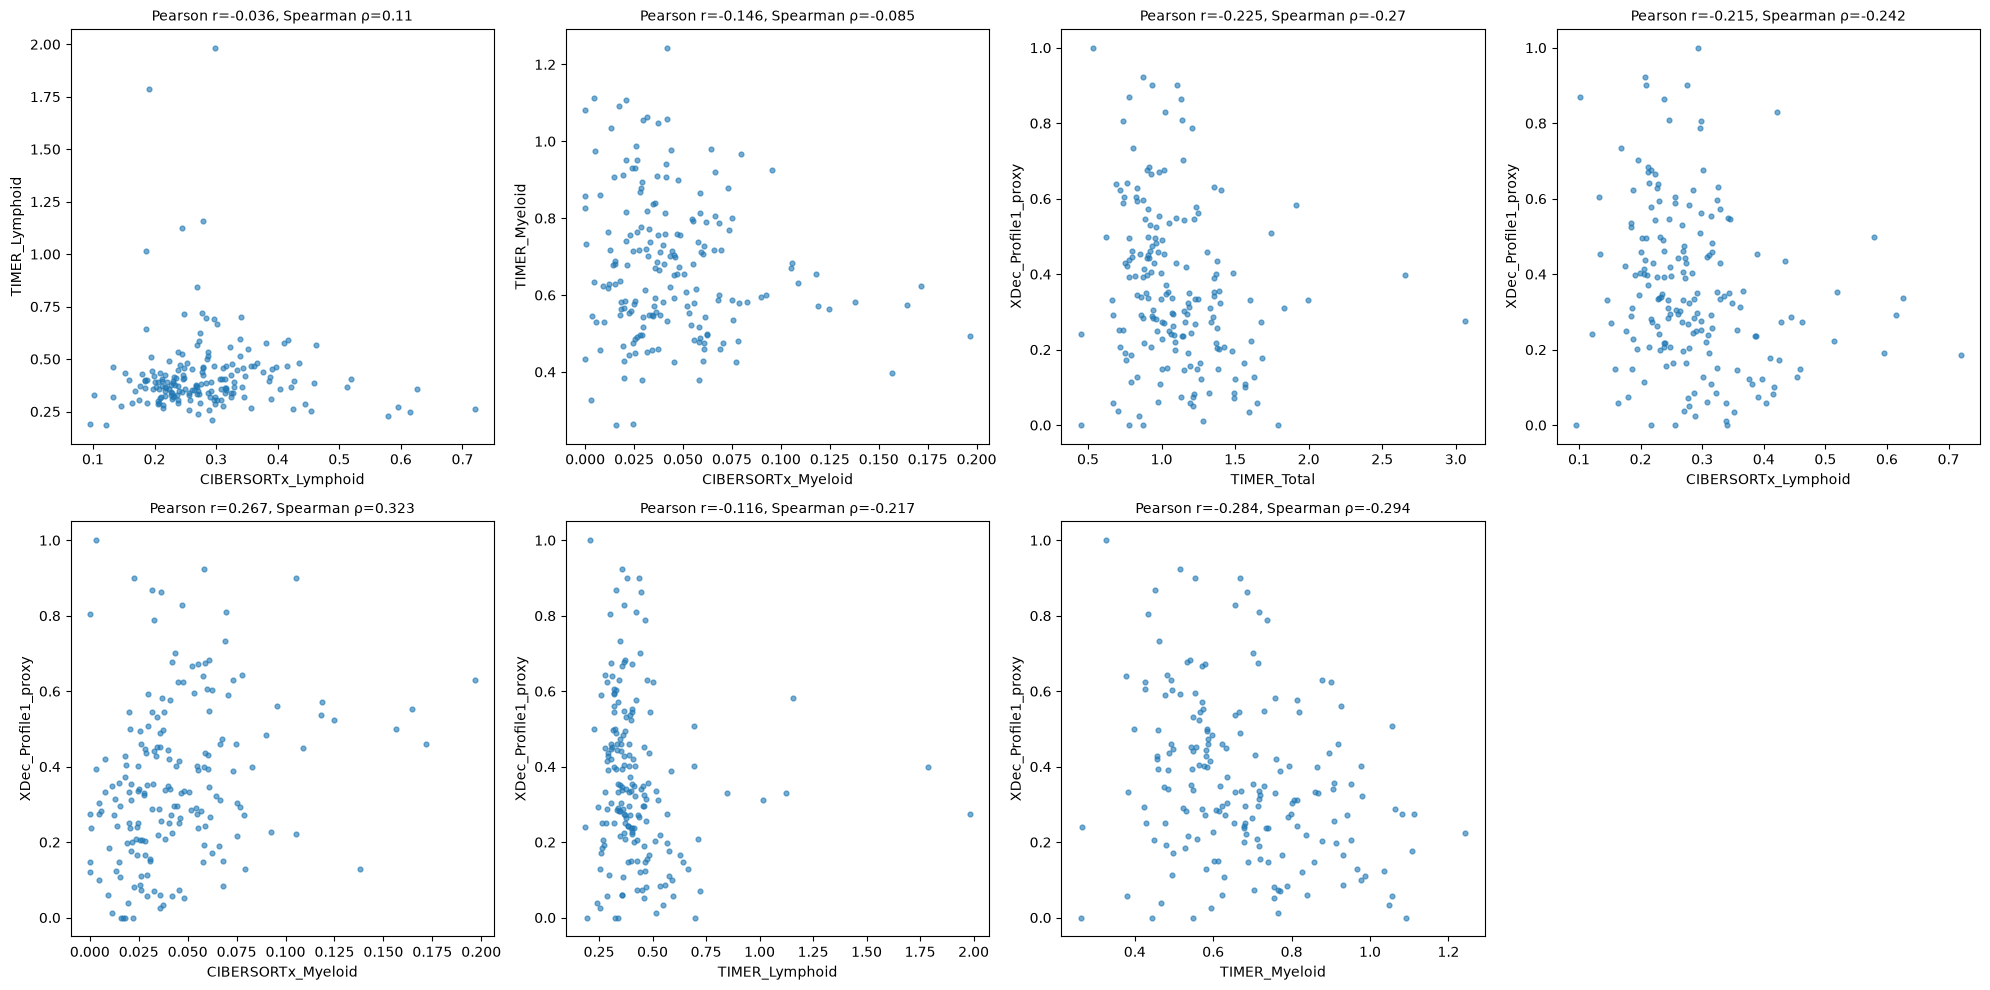

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for ax, (a, b) in zip(axes, pairs):
    x, y = merged[a], merged[b]
    ax.scatter(x, y, s=12, alpha=0.6)
    r = corr_df.loc[corr_df["comparison"] == f"{a} vs {b}", "pearson_r"].values[0]
    rho = corr_df.loc[corr_df["comparison"] == f"{a} vs {b}", "spearman_r"].values[0]
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"Pearson r={r}, Spearman \u03c1={rho}", fontsize=10)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "scatter_comparisons.png"), dpi=150)
plt.show()

**Interpretation:**
* **CIBERSORTx (Peng reference) and TIMER no longer agree on lymphocyte content** (r=-0.036, n.s.) - a reversal from the earlier LM22 run, where the same two tools agreed moderately (r=0.535, p=7.7e-15). The two CIBERSORTx signature-matrix choices disagree with *each other* on the identical 182 samples (LM22-Lymphoid vs. Peng-Lymphoid: r=-0.204, p=0.006).
* **Myeloid content agreement is weak-to-negative** (r=-0.146, p=0.050, borderline) - no better than the LM22 run's null result (r=0.063, n.s.).
* **XDec's Profile_1 proxy still does not positively track either tool** - weakly *negatively* correlated with TIMER (r=-0.225 to -0.284) and with CIBERSORTx-Peng's lymphoid score (r=-0.215), though now weakly *positively* correlated with CIBERSORTx-Peng's myeloid score (r=0.267) - a pattern not seen with LM22 (r=0.008). Consistent with Profile_1 being confounded with ductal/tumor-purity signal rather than being a clean immune readout, and with CIBERSORTx-Peng's "myeloid leukocyte" column itself not being a clean immune signal either (see Part 3). **Do not use XDec's unsupervised Profile_1 (k=3) as an immune-infiltration proxy** without first deconfounding it - notebook 07 Section 2 below finds a cleaner alternative at k=8.

## Part 3: CIBERSORTx-based lymphoid tertile DEA

CIBERSORTx now runs with a custom signature matrix built from the Peng et al. single-cell reference (notebook 05) rather than the default LM22 matrix, and `data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/CIBERSORTx_Adjusted.txt` (182 samples x 10 Peng-reference cell-type fractions) has been produced. This section generates CIBERSORTx's own tertile-split DE + GO/KEGG enrichment result, applying the same recipe as notebook 07 Sections 2-3 (XDec, TIMER), using CIBERSORTx's Peng-reference lymphoid-lineage fractions. The earlier LM22-based version of this section is archived (`data/deconvolution/cibersortx/archive_LM22/`, `archive/07_three_tool_eda_LM22_20261102_013437.ipynb`).

**Kernel note:** as in notebook 07 Section 3, the cells below are **R**, executed once via `~/.pixi/envs/r-base/bin/Rscript` from the `progress/` working directory (this notebook's own kernel is Python 3) and pasted here with their real captured output intact. To re-execute, switch the kernel to R (`pixi r-base`) first; they're self-contained given `data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/CIBERSORTx_Adjusted.txt` and `data/processed/TCGA-PAAD_TPM_raw.tsv` on disk (re-derive `ciber_dir <- "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx"` first, as in notebook 05).

### Methodology

This applies notebook 07 Section 3's TIMER recipe to CIBERSORTx's independently-computed Peng-reference fractions.

**Cell type match:** CIBERSORTx has no single "lymphoid" column; here it is the sum of the two Peng reference classes that map to lymphoid lineage - **T cell** and **lymphocyte of B lineage**. Unlike the earlier LM22 run's 12-column breakdown (naive/memory B, 7 T-cell subsets, NK resting/activated), the Peng reference gives no finer T-cell-subset or NK split - this is the coarsest of the three tools' lymphoid definitions used in this notebook. It is, however, built from the **identical single-cell reference** XDec's Profile_5 ("Lymphocyte (B+T)") uses - in principle the most directly comparable of the three to XDec, which makes Part 3's Result below (no replication of XDec's signal) a genuine disagreement between two tools sharing the same reference, not just a reference-mismatch artifact.

**Same methodological caveat as notebook 07 Section 3:** CIBERSORTx (like TIMER) outputs only cell-type fractions, not a Stage-2-equivalent cell-type-specific expression estimate, so this DEA is again necessarily done on **bulk** TPM between the high/low groups, not on a deconvolved cell-type-isolated profile the way XDec's Option 4 was.

**Sample ID note:** CIBERSORTx's `Mixture` column is already dash-formatted (e.g. `TCGA-IB-7888-01A-11R-2156-07`) and matches `TCGA-PAAD_TPM_raw.tsv`'s column headers exactly - no `norm_id()`-style dot-to-dash normalization needed here, unlike the Python harmonization used for XDec/TIMER in Part 2.

In [ ]:
library(matrixStats)

ciber_dir <- "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx"
cbx <- read.delim(file.path(ciber_dir, "CIBERSORTx_Adjusted.txt"), check.names = FALSE)

LYMPHOID_PENG <- c("T cell", "lymphocyte of B lineage")

lymphoid_score <- rowSums(cbx[, LYMPHOID_PENG])
names(lymphoid_score) <- cbx$Mixture

sample_type <- substr(sapply(strsplit(names(lymphoid_score), "-"), `[`, 4), 1, 2)
lymphoid_tumor <- lymphoid_score[sample_type == "01"]
cat("n tumor:", length(lymphoid_tumor), "\n")

q33 <- quantile(lymphoid_tumor, 1/3)
q67 <- quantile(lymphoid_tumor, 2/3)
low_samples  <- names(lymphoid_tumor)[lymphoid_tumor <= q33]
high_samples <- names(lymphoid_tumor)[lymphoid_tumor >= q67]
cat(sprintf("q33=%.4f q67=%.4f  n_low=%d  n_high=%d\n", q33, q67, length(low_samples), length(high_samples)))


n tumor: 178 
q33=0.2341 q67=0.2974  n_low=60  n_high=60


In [ ]:
tertile_dir <- file.path(ciber_dir, "lymphoid_tertile")
dir.create(tertile_dir, recursive = TRUE, showWarnings = FALSE)
de_path <- file.path(tertile_dir, "CIBERSORTx_lymphoid_tertile_DE_genes.tsv")

if (!file.exists(de_path)) {
  tpm <- as.matrix(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1, check.names = FALSE))

  low_expr  <- log2(tpm[, low_samples]  + 1)
  high_expr <- log2(tpm[, high_samples] + 1)

  n_low  <- ncol(low_expr);  n_high <- ncol(high_expr)
  m_low  <- rowMeans2(low_expr);  v_low  <- rowVars(low_expr)
  m_high <- rowMeans2(high_expr); v_high <- rowVars(high_expr)

  se <- sqrt(v_low / n_low + v_high / n_high)
  t_stat <- (m_high - m_low) / se
  df <- (v_low / n_low + v_high / n_high)^2 /
        ((v_low / n_low)^2 / (n_low - 1) + (v_high / n_high)^2 / (n_high - 1))
  pval <- 2 * pt(-abs(t_stat), df)

  mean_high_raw <- rowMeans2(tpm[, high_samples])
  mean_low_raw  <- rowMeans2(tpm[, low_samples])
  log2fc <- log2((mean_high_raw + 1) / (mean_low_raw + 1))

  de <- data.frame(gene = rownames(tpm), mean_high = mean_high_raw, mean_low = mean_low_raw,
                    t = t_stat, pval = pval, log2fc = log2fc)
  de <- de[!is.na(de$pval), ]
  de_sig <- de[de$pval < 0.05 & abs(de$log2fc) >= log2(5), ]
  de_sig <- de_sig[order(de_sig$log2fc), ]

  write.table(de_sig, de_path, sep = "\t", quote = FALSE, row.names = FALSE)
}

de_sig <- read.delim(de_path)
cat(sprintf("DE genes: %d  up in high: %d  up in low: %d\n",
            nrow(de_sig), sum(de_sig$log2fc > 0), sum(de_sig$log2fc < 0)))


DE genes: 26  up in high: 17  up in low: 9


In [ ]:
suppressMessages({
  library(clusterProfiler)
  library(org.Hs.eg.db)
})

universe_full <- rownames(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1))
up_high <- de_sig$gene[de_sig$log2fc > 0]
up_low  <- de_sig$gene[de_sig$log2fc < 0]

run_enrich <- function(genes, label) {
  if (length(genes) < 5) { cat("\n===", label, "- too few genes, skip ===\n"); return(invisible(NULL)) }
  ego <- tryCatch(enrichGO(gene = genes, universe = universe_full, OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
                   ont = "BP", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "GO:BP top 8 (n=", length(genes), ") ===\n")
  if (is.null(ego) || nrow(ego@result) == 0) { cat("No significant terms.\n") } else {
    print(head(as.data.frame(ego)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ego), file.path(tertile_dir, paste0("GO_BP_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
  entrez <- tryCatch(bitr(genes, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db)$ENTREZID, error = function(e) character(0))
  ekegg <- tryCatch(enrichKEGG(gene = entrez, organism = "hsa", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "KEGG top 8 ===\n")
  if (is.null(ekegg) || nrow(ekegg@result) == 0) { cat("No significant pathways.\n") } else {
    print(head(as.data.frame(ekegg)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ekegg), file.path(tertile_dir, paste0("KEGG_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
}

run_enrich(up_high, "CIBERSORTx_lymphoid_UpInHigh")
run_enrich(up_low,  "CIBERSORTx_lymphoid_UpInLow")



=== CIBERSORTx_lymphoid_UpInHigh GO:BP top 8 (n= 17 ) ===
                                                             Description
GO:0009306                                             protein secretion
GO:0035592 establishment of protein localization to extracellular region
GO:0071692                  protein localization to extracellular region
GO:0007218                                neuropeptide signaling pathway
GO:0099558                              maintenance of synapse structure
           GeneRatio    p.adjust Count
GO:0009306      5/16 0.001985995     5
GO:0035592      5/16 0.001985995     5
GO:0071692      5/16 0.001985995     5
GO:0007218      3/16 0.010854515     3
GO:0099558      2/16 0.024346119     2
'select()' returned 1:1 mapping between keys and columns
Reading KEGG annotation online: "https://rest.kegg.jp/link/hsa/pathway"...
Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/hsa"...

=== CIBERSORTx_lymphoid_UpInHigh KEGG top 8 ===
No significan

### Result: CIBERSORTx-based lymphoid tertile DEA (Peng reference)

n low / n high = 60 / 60. DE genes: 26 (17 up-high / 9 up-low). Unlike the earlier LM22 run (37 genes, dominated by B cell receptor signaling / hematopoietic-lineage terms), this split shows **no immune signature at all**: the only significant GO:BP terms (up-high, 5 terms) are protein secretion, establishment/localization of protein to the extracellular region, neuropeptide signaling pathway, and maintenance of synapse structure - driven by `SSTR2`, `CARTPT`, `PPY`, `GPR119`, `CBLN1`, `SCG2`, `C1QL1`, a set of pancreatic neuroendocrine/secretory genes, not immune genes. No KEGG pathway reached significance in either direction, and no GO:BP term reached significance for up-low.

CIBERSORTx's Peng-reference "lymphoid" fractions (T cell + lymphocyte of B lineage) do not recover the adaptive-immunity signal that both XDec's Profile_5 and TIMER's lymphoid score independently recover on the same cohort. The most likely explanation: in notebook 05's custom signature matrix, "enteroendocrine cell" and "pancreatic acinar cell" have the largest mean fractions (~0.20-0.24) of all 10 classes, so the lymphoid tertile split here is plausibly tracking residual compositional confounding with the dominant endocrine/acinar signal rather than cleanly isolating lymphocyte content - despite being built from the same single-cell reference as XDec's (independently-validated) Lymphocyte profile. The side-by-side comparison against XDec's and TIMER's results is in Part 7.

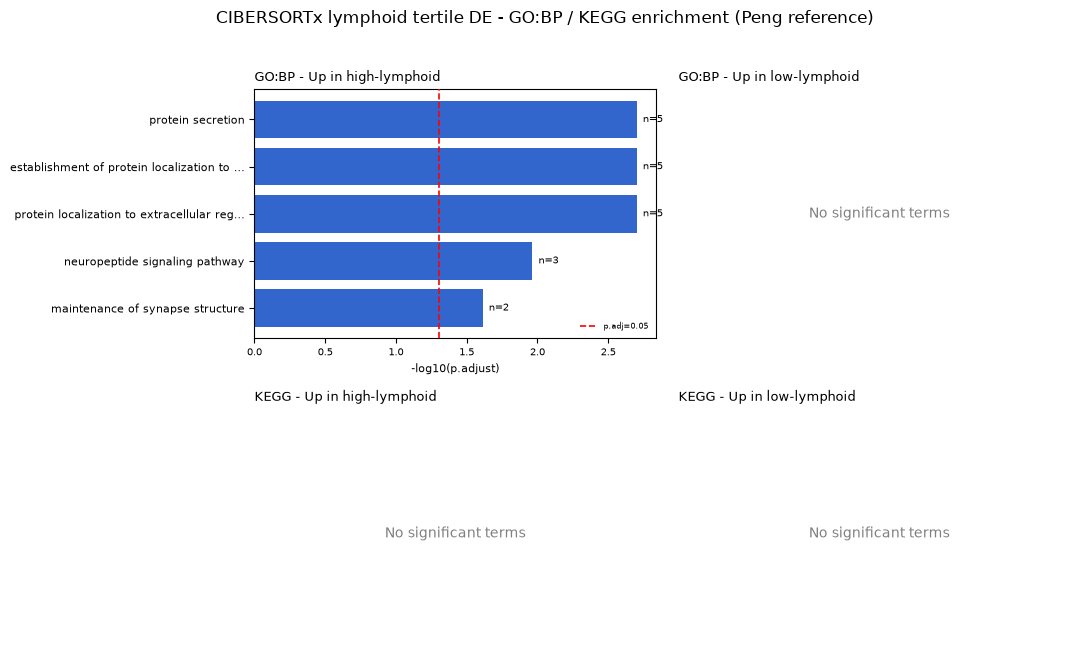

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


def wrap_label(s, width=42):
    s = str(s)
    return s if len(s) <= width else s[: width - 1] + "\u2026"


def read_terms(path, top_n=6):
    if not os.path.exists(path):
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = pd.read_csv(path, sep="\t")
    if df.empty or "Description" not in df.columns:
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = df.sort_values("p.adjust").head(top_n).copy()
    df["neglog10_padj"] = -np.log10(df["p.adjust"])
    return df


def panel(ax, path, title, color):
    df = read_terms(path)
    if df.empty:
        ax.text(0.5, 0.5, "No significant terms", ha="center", va="center",
                fontsize=10, color="gray", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    else:
        labels = [wrap_label(d) for d in df["Description"]][::-1]
        vals = df["neglog10_padj"].values[::-1]
        counts = df["Count"].values[::-1]
        y = np.arange(len(labels))
        ax.barh(y, vals, color=color, edgecolor="none")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_xlabel("-log10(p.adjust)", fontsize=8)
        for yi, (v, c) in enumerate(zip(vals, counts)):
            ax.text(v, yi, f"  n={c}", va="center", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        thresh = -np.log10(0.05)
        ax.axvline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
    ax.set_title(title, fontsize=9.5, loc="left")

cbx_dir = "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/lymphoid_tertile"
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
panel(axes[0, 0], f"{cbx_dir}/GO_BP_CIBERSORTx_lymphoid_UpInHigh.tsv", "GO:BP - Up in high-lymphoid", "#3366cc")
panel(axes[0, 1], f"{cbx_dir}/GO_BP_CIBERSORTx_lymphoid_UpInLow.tsv", "GO:BP - Up in low-lymphoid", "#999999")
panel(axes[1, 0], f"{cbx_dir}/KEGG_CIBERSORTx_lymphoid_UpInHigh.tsv", "KEGG - Up in high-lymphoid", "#3366cc")
panel(axes[1, 1], f"{cbx_dir}/KEGG_CIBERSORTx_lymphoid_UpInLow.tsv", "KEGG - Up in low-lymphoid", "#999999")
fig.suptitle("CIBERSORTx lymphoid tertile DE - GO:BP / KEGG enrichment (Peng reference)", fontsize=12, y=1.02)
fig.tight_layout()
os.makedirs(f"{cbx_dir}/figures", exist_ok=True)
plt.savefig(f"{cbx_dir}/figures/lymphoid_tertile_enrichment.png", dpi=150, bbox_inches="tight")
plt.show()

## Part 4: Myeloid tertile DEA (TIMER + CIBERSORTx)

Part 2 flagged CIBERSORTx-Peng's myeloid score as showing an unusual correlation pattern (borderline-negative with TIMER's myeloid score, positively correlated with XDec's confounded Profile_1, unlike the earlier LM22 run). This section runs the same tertile-split DE + GO/KEGG recipe on the **myeloid** axis for both tools that have one - TIMER's summed Neutrophil/Macrophage/DC score, and CIBERSORTx-Peng's single "myeloid leukocyte" column. **XDec has no myeloid axis to cross-validate against**: Option 2's marker-gene identification (notebook 07 Section 2) cleanly labeled only 3 of k=8's 8 profiles (Fibroblast/CAF, Lymphocyte, Enteroendocrine) - none of the remaining unlabeled profiles was identified as myeloid.

**Kernel note:** as in notebook 07 Section 3 and Part 3 of this notebook, the cells below are **R**, executed once via `~/.pixi/envs/r-base/bin/Rscript` from the `progress/` working directory and pasted here with their real captured output intact.

### Methodology

Same recipe as notebook 07 Section 3 and Part 3 of this notebook (bulk-TPM tertile split by deconvolved myeloid score, log2FC + Welch's t-test, `p<0.05 & |log2FC|>=log2(5)`, GO:BP/KEGG enrichment on the up-high/up-low gene sets), applied to:
* **TIMER:** `Neutrophil + Macrophage + DC` (summed), the direct myeloid analog of notebook 07 Section 3's lymphoid score.
* **CIBERSORTx (Peng reference):** the single `myeloid leukocyte` column - Peng's reference has no finer myeloid-subtype split (no monocyte/macrophage-polarization/DC/mast/eosinophil/neutrophil breakdown, unlike LM22's 10-column myeloid set used in the archived LM22 run).

In [ ]:
library(matrixStats)

score_path <- file.path("data/deconvolution/timer_real_full", "results", "score_matrix.txt")
timer_mat <- as.matrix(read.delim(score_path, row.names = 1, check.names = FALSE))
colnames(timer_mat) <- gsub("\\.", "-", colnames(timer_mat))

myeloid_score <- colSums(timer_mat[c("Neutrophil", "Macrophage", "DC"), ])
sample_type <- substr(sapply(strsplit(names(myeloid_score), "-"), `[`, 4), 1, 2)
myeloid_tumor <- myeloid_score[sample_type == "01"]
cat("n tumor:", length(myeloid_tumor), "\n")

q33 <- quantile(myeloid_tumor, 1/3)
q67 <- quantile(myeloid_tumor, 2/3)
low_samples  <- names(myeloid_tumor)[myeloid_tumor <= q33]
high_samples <- names(myeloid_tumor)[myeloid_tumor >= q67]
cat(sprintf("q33=%.4f q67=%.4f  n_low=%d  n_high=%d\n", q33, q67, length(low_samples), length(high_samples)))


n tumor: 178 
q33=0.5711 q67=0.7202  n_low=60  n_high=60


In [ ]:
timer_outdir <- "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102"
tertile_dir <- file.path(timer_outdir, "myeloid_tertile")
dir.create(tertile_dir, recursive = TRUE, showWarnings = FALSE)
de_path <- file.path(tertile_dir, "TIMER_myeloid_tertile_DE_genes.tsv")

if (!file.exists(de_path)) {
  tpm <- as.matrix(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1, check.names = FALSE))

  low_expr  <- log2(tpm[, low_samples]  + 1)
  high_expr <- log2(tpm[, high_samples] + 1)

  n_low  <- ncol(low_expr);  n_high <- ncol(high_expr)
  m_low  <- rowMeans2(low_expr);  v_low  <- rowVars(low_expr)
  m_high <- rowMeans2(high_expr); v_high <- rowVars(high_expr)

  se <- sqrt(v_low / n_low + v_high / n_high)
  t_stat <- (m_high - m_low) / se
  df <- (v_low / n_low + v_high / n_high)^2 /
        ((v_low / n_low)^2 / (n_low - 1) + (v_high / n_high)^2 / (n_high - 1))
  pval <- 2 * pt(-abs(t_stat), df)

  mean_high_raw <- rowMeans2(tpm[, high_samples])
  mean_low_raw  <- rowMeans2(tpm[, low_samples])
  log2fc <- log2((mean_high_raw + 1) / (mean_low_raw + 1))

  de <- data.frame(gene = rownames(tpm), mean_high = mean_high_raw, mean_low = mean_low_raw,
                    t = t_stat, pval = pval, log2fc = log2fc)
  de <- de[!is.na(de$pval), ]
  de_sig <- de[de$pval < 0.05 & abs(de$log2fc) >= log2(5), ]
  de_sig <- de_sig[order(de_sig$log2fc), ]

  write.table(de_sig, de_path, sep = "\t", quote = FALSE, row.names = FALSE)
}

de_sig <- read.delim(de_path)
cat(sprintf("DE genes: %d  up in high: %d  up in low: %d\n",
            nrow(de_sig), sum(de_sig$log2fc > 0), sum(de_sig$log2fc < 0)))


DE genes: 161  up in high: 147  up in low: 14


In [ ]:
suppressMessages({
  library(clusterProfiler)
  library(org.Hs.eg.db)
})

universe_full <- rownames(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1))
up_high <- de_sig$gene[de_sig$log2fc > 0]
up_low  <- de_sig$gene[de_sig$log2fc < 0]

run_enrich <- function(genes, label) {
  if (length(genes) < 5) { cat("\n===", label, "- too few genes, skip ===\n"); return(invisible(NULL)) }
  ego <- tryCatch(enrichGO(gene = genes, universe = universe_full, OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
                   ont = "BP", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "GO:BP top 8 (n=", length(genes), ") ===\n")
  if (is.null(ego) || nrow(ego@result) == 0) { cat("No significant terms.\n") } else {
    print(head(as.data.frame(ego)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ego), file.path(tertile_dir, paste0("GO_BP_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
  entrez <- tryCatch(bitr(genes, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db)$ENTREZID, error = function(e) character(0))
  ekegg <- tryCatch(enrichKEGG(gene = entrez, organism = "hsa", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2), error = function(e) NULL)
  cat("\n===", label, "KEGG top 8 ===\n")
  if (is.null(ekegg) || nrow(ekegg@result) == 0) { cat("No significant pathways.\n") } else {
    print(head(as.data.frame(ekegg)[, c("Description", "GeneRatio", "p.adjust", "Count")], 8))
    write.table(as.data.frame(ekegg), file.path(tertile_dir, paste0("KEGG_", label, ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  }
}

run_enrich(up_high, "TIMER_myeloid_UpInHigh")
run_enrich(up_low,  "TIMER_myeloid_UpInLow")



=== TIMER_myeloid_UpInHigh GO:BP top 8 (n= 147 ) ===
                                                                                                                         Description
GO:0016064                                                                                   immunoglobulin mediated immune response
GO:0019724                                                                                                  B cell mediated immunity
GO:0002460 adaptive immune response based on somatic recombination of immune receptors built from immunoglobulin superfamily domains
GO:0002449                                                                                              lymphocyte mediated immunity
GO:0002443                                                                                               leukocyte mediated immunity
GO:0006959                                                                                                   humoral immune response
GO:0002429     

In [ ]:
ciber_dir <- "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx"
cbx <- read.delim(file.path(ciber_dir, "CIBERSORTx_Adjusted.txt"), check.names = FALSE)

myeloid_score <- cbx[["myeloid leukocyte"]]
names(myeloid_score) <- cbx$Mixture

sample_type <- substr(sapply(strsplit(names(myeloid_score), "-"), `[`, 4), 1, 2)
myeloid_tumor <- myeloid_score[sample_type == "01"]
cat("n tumor:", length(myeloid_tumor), "\n")

q33 <- quantile(myeloid_tumor, 1/3)
q67 <- quantile(myeloid_tumor, 2/3)
low_samples  <- names(myeloid_tumor)[myeloid_tumor <= q33]
high_samples <- names(myeloid_tumor)[myeloid_tumor >= q67]
cat(sprintf("q33=%.4f q67=%.4f  n_low=%d  n_high=%d\n", q33, q67, length(low_samples), length(high_samples)))


n tumor: 178 
q33=0.0284 q67=0.0522  n_low=60  n_high=60


In [ ]:
tertile_dir <- file.path(ciber_dir, "myeloid_tertile")
dir.create(tertile_dir, recursive = TRUE, showWarnings = FALSE)
de_path <- file.path(tertile_dir, "CIBERSORTx_myeloid_tertile_DE_genes.tsv")

if (!file.exists(de_path)) {
  tpm <- as.matrix(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1, check.names = FALSE))
  low_expr  <- log2(tpm[, low_samples]  + 1)
  high_expr <- log2(tpm[, high_samples] + 1)
  n_low  <- ncol(low_expr);  n_high <- ncol(high_expr)
  m_low  <- rowMeans2(low_expr);  v_low  <- rowVars(low_expr)
  m_high <- rowMeans2(high_expr); v_high <- rowVars(high_expr)
  se <- sqrt(v_low / n_low + v_high / n_high)
  t_stat <- (m_high - m_low) / se
  df <- (v_low / n_low + v_high / n_high)^2 /
        ((v_low / n_low)^2 / (n_low - 1) + (v_high / n_high)^2 / (n_high - 1))
  pval <- 2 * pt(-abs(t_stat), df)
  mean_high_raw <- rowMeans2(tpm[, high_samples])
  mean_low_raw  <- rowMeans2(tpm[, low_samples])
  log2fc <- log2((mean_high_raw + 1) / (mean_low_raw + 1))
  de <- data.frame(gene = rownames(tpm), mean_high = mean_high_raw, mean_low = mean_low_raw,
                    t = t_stat, pval = pval, log2fc = log2fc)
  de <- de[!is.na(de$pval), ]
  de_sig <- de[de$pval < 0.05 & abs(de$log2fc) >= log2(5), ]
  de_sig <- de_sig[order(de_sig$log2fc), ]
  write.table(de_sig, de_path, sep = "\t", quote = FALSE, row.names = FALSE)
}

de_sig <- read.delim(de_path)
cat(sprintf("DE genes: %d  up in high: %d  up in low: %d\n",
            nrow(de_sig), sum(de_sig$log2fc > 0), sum(de_sig$log2fc < 0)))


DE genes: 34  up in high: 13  up in low: 21


In [ ]:
up_high <- de_sig$gene[de_sig$log2fc > 0]
up_low  <- de_sig$gene[de_sig$log2fc < 0]

run_enrich(up_high, "CIBERSORTx_myeloid_UpInHigh")
run_enrich(up_low,  "CIBERSORTx_myeloid_UpInLow")



=== CIBERSORTx_myeloid_UpInHigh GO:BP top 8 (n= 13 ) ===
                                               Description GeneRatio
GO:0031424                                  keratinization      5/10
GO:0030216                    keratinocyte differentiation      5/10
GO:0009913                  epidermal cell differentiation      5/10
GO:0043588                                skin development      5/10
GO:0008544                           epidermis development      5/10
GO:0045109              intermediate filament organization      3/10
GO:0045104 intermediate filament cytoskeleton organization      3/10
GO:0045103             intermediate filament-based process      3/10
               p.adjust Count
GO:0031424 3.905079e-08     5
GO:0030216 1.078787e-06     5
GO:0009913 4.055570e-06     5
GO:0043588 1.088488e-05     5
GO:0008544 2.300938e-05     5
GO:0045109 1.327316e-04     3
GO:0045104 2.180436e-04     3
GO:0045103 2.180436e-04     3

=== CIBERSORTx_myeloid_UpInHigh KEGG top 8 ===
   

### Result: Myeloid tertile DEA (TIMER + CIBERSORTx-Peng)

**TIMER:** n low/high = 60/60. DE genes: 161 (147 up-high/14 up-low). The up-high signature, however, is **not myeloid-specific** - it is nearly identical in flavor to notebook 07 Section 3's lymphoid signature (immunoglobulin-mediated immune response, B cell mediated immunity, Hematopoietic cell lineage, Primary immunodeficiency, B cell receptor signaling pathway), with only "Phagocytosis" and "Complement and coagulation cascades" hinting at anything myeloid-specific. This is consistent with lymphoid and myeloid infiltration genuinely co-varying in this cohort (tumors with more immune infiltration tend to have more of both), rather than TIMER's myeloid score being a clean, orthogonal readout of myeloid content alone.

**CIBERSORTx (Peng reference):** n low/high = 60/60. DE genes: 34 (13 up-high/21 up-low) - no overlap at all with TIMER's result, and no myeloid-specific biology in either direction. Up-high: keratinization/keratinocyte differentiation/skin development/intermediate filament organization - an epithelial-differentiation signature unrelated to any immune cell type. Up-low: digestion/pancreatic secretion/lipid and vitamin absorption - the same exocrine-pancreas axis seen confounding Part 3's "lymphoid" result. CIBERSORTx-Peng's "myeloid leukocyte" fraction does not recover myeloid biology, and (unlike TIMER's) doesn't even recover a generically immune-flavored signature.

**No XDec comparison is possible** - XDec's k=8 factorization did not cleanly identify a myeloid-labeled profile, so there is no third, independently-computed myeloid axis to validate either tool's result against.

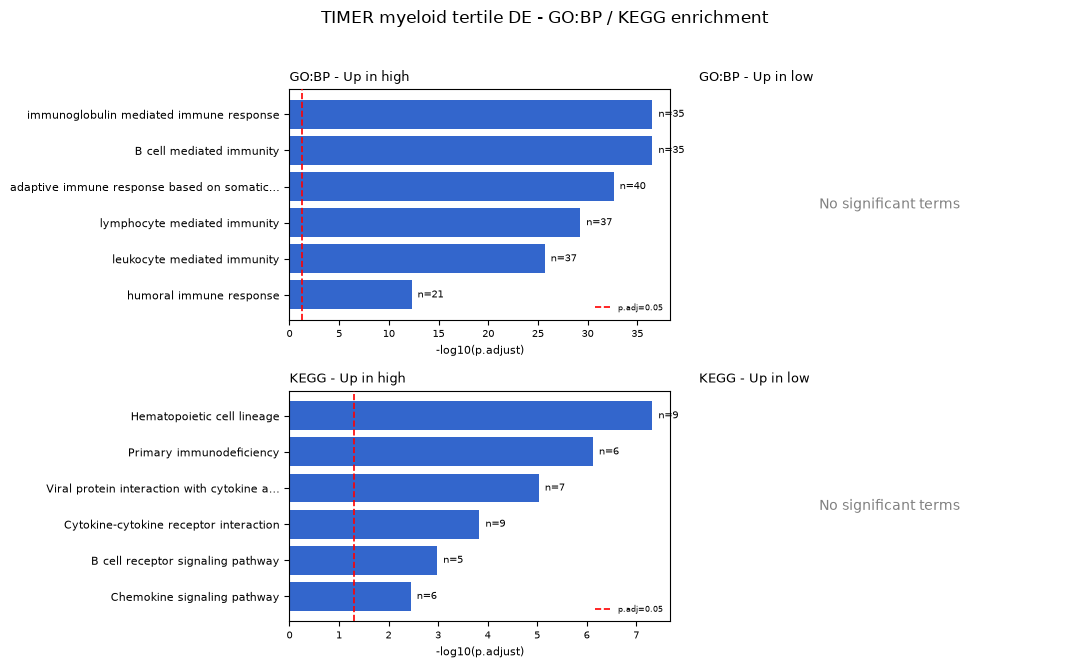

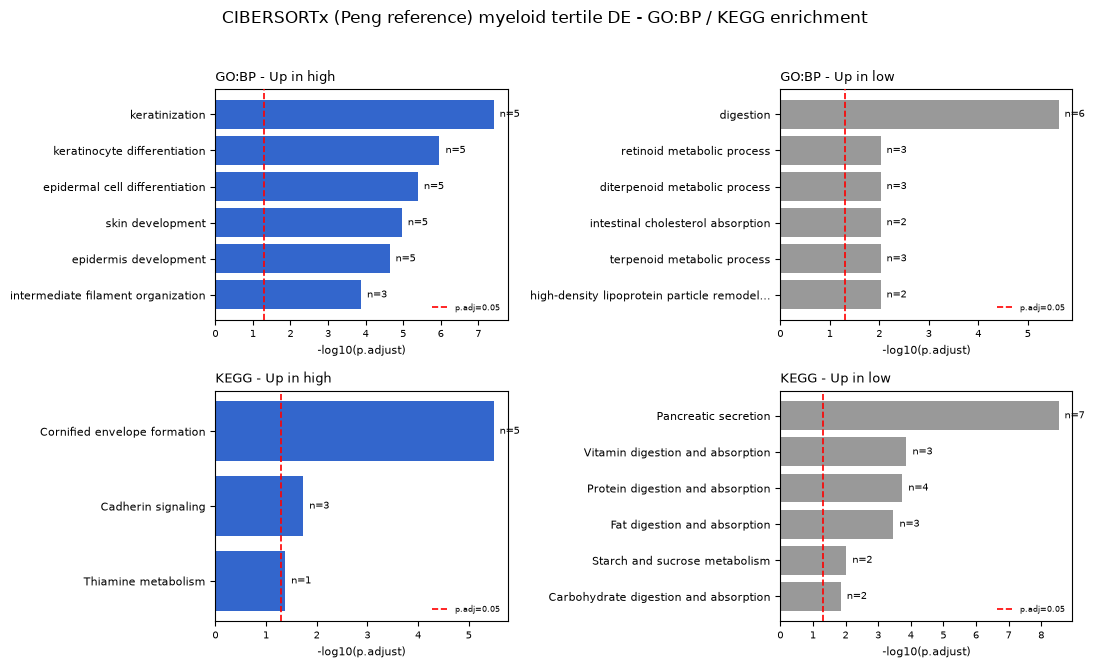

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


def wrap_label(s, width=42):
    s = str(s)
    return s if len(s) <= width else s[: width - 1] + "\u2026"


def read_terms(path, top_n=6):
    if not os.path.exists(path):
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = pd.read_csv(path, sep="\t")
    if df.empty or "Description" not in df.columns:
        return pd.DataFrame(columns=["Description", "p.adjust", "Count"])
    df = df.sort_values("p.adjust").head(top_n).copy()
    df["neglog10_padj"] = -np.log10(df["p.adjust"])
    return df


def panel(ax, path, title, color):
    df = read_terms(path)
    if df.empty:
        ax.text(0.5, 0.5, "No significant terms", ha="center", va="center",
                fontsize=10, color="gray", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    else:
        labels = [wrap_label(d) for d in df["Description"]][::-1]
        vals = df["neglog10_padj"].values[::-1]
        counts = df["Count"].values[::-1]
        y = np.arange(len(labels))
        ax.barh(y, vals, color=color, edgecolor="none")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_xlabel("-log10(p.adjust)", fontsize=8)
        for yi, (v, c) in enumerate(zip(vals, counts)):
            ax.text(v, yi, f"  n={c}", va="center", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        thresh = -np.log10(0.05)
        ax.axvline(thresh, color="red", linestyle="--", linewidth=1.2, zorder=5, label="p.adj=0.05")
        ax.legend(loc="lower right", fontsize=6, frameon=False)
    ax.set_title(title, fontsize=9.5, loc="left")


def four_panel(tertile_dir, prefix, suptitle):
    fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
    panel(axes[0, 0], f"{tertile_dir}/GO_BP_{prefix}_UpInHigh.tsv", "GO:BP - Up in high", "#3366cc")
    panel(axes[0, 1], f"{tertile_dir}/GO_BP_{prefix}_UpInLow.tsv", "GO:BP - Up in low", "#999999")
    panel(axes[1, 0], f"{tertile_dir}/KEGG_{prefix}_UpInHigh.tsv", "KEGG - Up in high", "#3366cc")
    panel(axes[1, 1], f"{tertile_dir}/KEGG_{prefix}_UpInLow.tsv", "KEGG - Up in low", "#999999")
    fig.suptitle(suptitle, fontsize=12, y=1.02)
    fig.tight_layout()
    plt.show()


four_panel("data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/myeloid_tertile", "TIMER_myeloid",
           "TIMER myeloid tertile DE - GO:BP / KEGG enrichment")
four_panel("data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/myeloid_tertile", "CIBERSORTx_myeloid",
           "CIBERSORTx (Peng reference) myeloid tertile DE - GO:BP / KEGG enrichment")

## Part 5: Fibroblast/CAF tertile DEA (CIBERSORTx)

XDec already has an independently-computed Fibroblast/CAF result at k=8 (Profile_2, notebook 07 Section 2: 206 DE genes, 10 up-high/196 up-low, no clean ECM/collagen signature recovered even there - see notebook 07 Section 2's Result). This section runs CIBERSORTx-Peng's own Fibroblast/CAF tertile-split DE + GO/KEGG, to see whether it recovers a cleaner (or at least a related) signal using the identical single-cell reference. **TIMER has no stromal/fibroblast score at all** (its 6 types are all immune lineages), so only CIBERSORTx can be compared against XDec here.

**Kernel note:** R, executed via `Rscript`, pasted with real output, as in Part 3-Part 4 of this notebook.

### Methodology

**Cell type match:** Peng's reference has two separate classes that could map to "Fibroblast/CAF" - `fibroblast` and `pancreatic stellate cell` (pancreatic CAFs are frequently derived from activated stellate cells). Per `data/deconvolution/xdec/stage1_with_refs_k8/correlation.tsv`, XDec's Profile_2 correlates weakly-positively with both (`fibroblast` r=0.153, `pancreatic stellate cell` r=0.115) and negatively with the epithelial/endocrine classes (`pancreatic acinar cell` r=-0.357, `enteroendocrine cell` r=-0.295) - consistent with a CAF/stromal identity, so both classes are **summed** here, same grouping logic as Part 2's lymphoid/myeloid totals.

In [ ]:
fibro_score <- rowSums(cbx[, c("fibroblast", "pancreatic stellate cell")])
names(fibro_score) <- cbx$Mixture

sample_type <- substr(sapply(strsplit(names(fibro_score), "-"), `[`, 4), 1, 2)
fibro_tumor <- fibro_score[sample_type == "01"]
cat("n tumor:", length(fibro_tumor), "\n")

q33 <- quantile(fibro_tumor, 1/3)
q67 <- quantile(fibro_tumor, 2/3)
low_samples  <- names(fibro_tumor)[fibro_tumor <= q33]
high_samples <- names(fibro_tumor)[fibro_tumor >= q67]
cat(sprintf("q33=%.4f q67=%.4f  n_low=%d  n_high=%d\n", q33, q67, length(low_samples), length(high_samples)))


n tumor: 178 
q33=0.0638 q67=0.1099  n_low=60  n_high=60


In [ ]:
tertile_dir <- file.path(ciber_dir, "fibroblast_tertile")
dir.create(tertile_dir, recursive = TRUE, showWarnings = FALSE)
de_path <- file.path(tertile_dir, "CIBERSORTx_fibroblast_tertile_DE_genes.tsv")

if (!file.exists(de_path)) {
  tpm <- as.matrix(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1, check.names = FALSE))
  low_expr  <- log2(tpm[, low_samples]  + 1)
  high_expr <- log2(tpm[, high_samples] + 1)
  n_low  <- ncol(low_expr);  n_high <- ncol(high_expr)
  m_low  <- rowMeans2(low_expr);  v_low  <- rowVars(low_expr)
  m_high <- rowMeans2(high_expr); v_high <- rowVars(high_expr)
  se <- sqrt(v_low / n_low + v_high / n_high)
  t_stat <- (m_high - m_low) / se
  df <- (v_low / n_low + v_high / n_high)^2 /
        ((v_low / n_low)^2 / (n_low - 1) + (v_high / n_high)^2 / (n_high - 1))
  pval <- 2 * pt(-abs(t_stat), df)
  mean_high_raw <- rowMeans2(tpm[, high_samples])
  mean_low_raw  <- rowMeans2(tpm[, low_samples])
  log2fc <- log2((mean_high_raw + 1) / (mean_low_raw + 1))
  de <- data.frame(gene = rownames(tpm), mean_high = mean_high_raw, mean_low = mean_low_raw,
                    t = t_stat, pval = pval, log2fc = log2fc)
  de <- de[!is.na(de$pval), ]
  de_sig <- de[de$pval < 0.05 & abs(de$log2fc) >= log2(5), ]
  de_sig <- de_sig[order(de_sig$log2fc), ]
  write.table(de_sig, de_path, sep = "\t", quote = FALSE, row.names = FALSE)
}

de_sig <- read.delim(de_path)
cat(sprintf("DE genes: %d  up in high: %d  up in low: %d\n",
            nrow(de_sig), sum(de_sig$log2fc > 0), sum(de_sig$log2fc < 0)))


DE genes: 153  up in high: 152  up in low: 1


In [ ]:
up_high <- de_sig$gene[de_sig$log2fc > 0]
up_low  <- de_sig$gene[de_sig$log2fc < 0]

run_enrich(up_high, "CIBERSORTx_fibroblast_UpInHigh")
run_enrich(up_low,  "CIBERSORTx_fibroblast_UpInLow")



=== CIBERSORTx_fibroblast_UpInHigh GO:BP top 8 (n= 152 ) ===
                                                                                                                         Description
GO:0016064                                                                                   immunoglobulin mediated immune response
GO:0019724                                                                                                  B cell mediated immunity
GO:0002460 adaptive immune response based on somatic recombination of immune receptors built from immunoglobulin superfamily domains
GO:0002449                                                                                              lymphocyte mediated immunity
GO:0002443                                                                                               leukocyte mediated immunity
GO:0050853                                                                                         B cell receptor signaling pathway
GO:0050

### Result: Fibroblast/CAF tertile DEA (CIBERSORTx-Peng) vs. XDec Profile_2

n low/high = 60/60. DE genes: 153 (152 up-high/1 up-low). **This does not recover a fibroblast/ECM/collagen signature at all** - it is essentially a copy of Part 3's "lymphoid" result: immunoglobulin-mediated immune response, B cell mediated immunity, B cell receptor signaling pathway, Hematopoietic cell lineage, Primary immunodeficiency. Nor does it match XDec's own Profile_2 result, which itself never recovered a clean ECM/collagen signature either (196 up-low genes enriched for negative regulation of apoptotic signaling / nucleotide transport, no significant KEGG terms in that direction; only 10 up-high genes, too few for enrichment).

**Neither tool cleanly validates a fibroblast/CAF-specific signal on this axis.** But CIBERSORTx's near-exact duplication of its own lymphoid result here is the more informative finding: it strongly suggests `fibroblast` + `pancreatic stellate cell` fractions are **colinear with `T cell` + `lymphocyte of B lineage`** in this custom signature matrix - i.e. CIBERSORTx-Peng's tertile split on "fibroblast content" is, in practice, splitting on roughly the same underlying axis as its "lymphoid content" split (plausibly a general stroma/immune-vs-tumor-epithelial compositional axis), not resolving fibroblasts as a distinct, orthogonal cell-type signal.

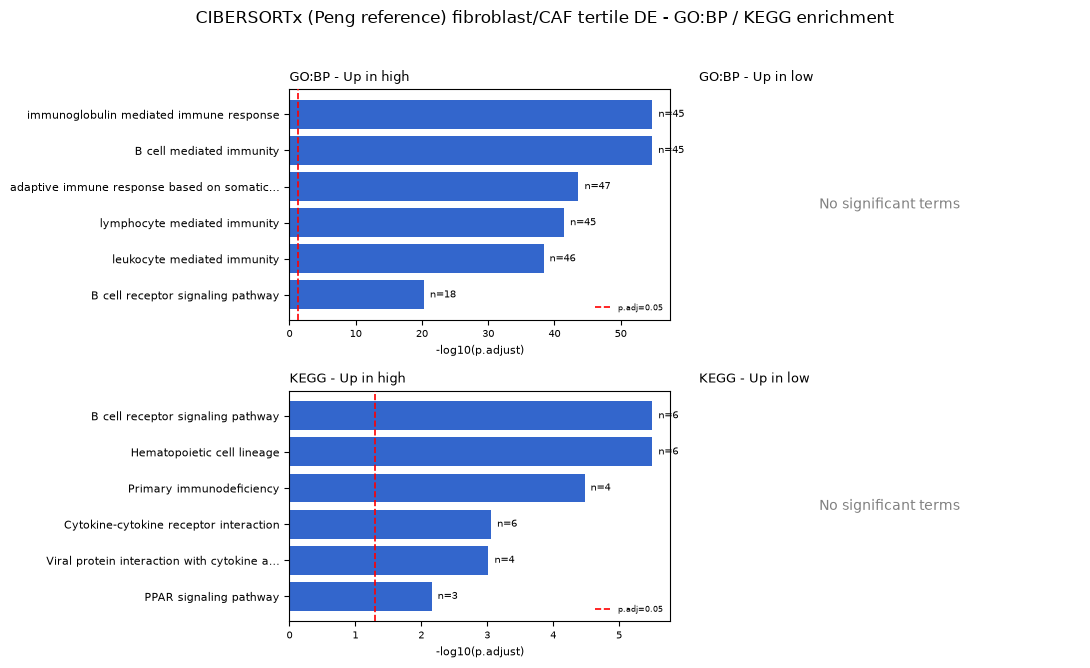

In [2]:
four_panel("data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/fibroblast_tertile", "CIBERSORTx_fibroblast",
           "CIBERSORTx (Peng reference) fibroblast/CAF tertile DE - GO:BP / KEGG enrichment")

## Part 6: Enteroendocrine tertile DEA (CIBERSORTx)

XDec's Profile_8 (Enteroendocrine, notebook 07 Section 2) is the cleanest of the three XDec biological validations: 666 DE genes (485 up-high), with top GO:BP terms neurotransmitter secretion, insulin secretion, and peptide hormone secretion - a textbook endocrine signature. This section tests whether CIBERSORTx-Peng's own `enteroendocrine cell` fraction, built from the same single-cell reference, reproduces it. As with Part 5, **TIMER has no comparable score** (immune-only), so this is CIBERSORTx vs. XDec only.

**Kernel note:** R, executed via `Rscript`, pasted with real output, as in Part 3-Part 5 of this notebook.

### Methodology

**Cell type match:** `enteroendocrine cell` is used directly - per `correlation.tsv`, it is XDec's Profile_8's single strongest positive correlate among all 10 Peng classes (r=0.303), with no other class close, so no summing/grouping judgment call is needed here (unlike lymphoid/myeloid/fibroblast).

In [ ]:
entero_score <- cbx[["enteroendocrine cell"]]
names(entero_score) <- cbx$Mixture

sample_type <- substr(sapply(strsplit(names(entero_score), "-"), `[`, 4), 1, 2)
entero_tumor <- entero_score[sample_type == "01"]
cat("n tumor:", length(entero_tumor), "\n")

q33 <- quantile(entero_tumor, 1/3)
q67 <- quantile(entero_tumor, 2/3)
low_samples  <- names(entero_tumor)[entero_tumor <= q33]
high_samples <- names(entero_tumor)[entero_tumor >= q67]
cat(sprintf("q33=%.4f q67=%.4f  n_low=%d  n_high=%d\n", q33, q67, length(low_samples), length(high_samples)))


n tumor: 178 
q33=0.1421 q67=0.2541  n_low=60  n_high=60


In [ ]:
tertile_dir <- file.path(ciber_dir, "enteroendocrine_tertile")
dir.create(tertile_dir, recursive = TRUE, showWarnings = FALSE)
de_path <- file.path(tertile_dir, "CIBERSORTx_enteroendocrine_tertile_DE_genes.tsv")

if (!file.exists(de_path)) {
  tpm <- as.matrix(read.delim("data/processed/TCGA-PAAD_TPM_raw.tsv", row.names = 1, check.names = FALSE))
  low_expr  <- log2(tpm[, low_samples]  + 1)
  high_expr <- log2(tpm[, high_samples] + 1)
  n_low  <- ncol(low_expr);  n_high <- ncol(high_expr)
  m_low  <- rowMeans2(low_expr);  v_low  <- rowVars(low_expr)
  m_high <- rowMeans2(high_expr); v_high <- rowVars(high_expr)
  se <- sqrt(v_low / n_low + v_high / n_high)
  t_stat <- (m_high - m_low) / se
  df <- (v_low / n_low + v_high / n_high)^2 /
        ((v_low / n_low)^2 / (n_low - 1) + (v_high / n_high)^2 / (n_high - 1))
  pval <- 2 * pt(-abs(t_stat), df)
  mean_high_raw <- rowMeans2(tpm[, high_samples])
  mean_low_raw  <- rowMeans2(tpm[, low_samples])
  log2fc <- log2((mean_high_raw + 1) / (mean_low_raw + 1))
  de <- data.frame(gene = rownames(tpm), mean_high = mean_high_raw, mean_low = mean_low_raw,
                    t = t_stat, pval = pval, log2fc = log2fc)
  de <- de[!is.na(de$pval), ]
  de_sig <- de[de$pval < 0.05 & abs(de$log2fc) >= log2(5), ]
  de_sig <- de_sig[order(de_sig$log2fc), ]
  write.table(de_sig, de_path, sep = "\t", quote = FALSE, row.names = FALSE)
}

de_sig <- read.delim(de_path)
cat(sprintf("DE genes: %d  up in high: %d  up in low: %d\n",
            nrow(de_sig), sum(de_sig$log2fc > 0), sum(de_sig$log2fc < 0)))


DE genes: 53  up in high: 38  up in low: 15


In [ ]:
up_high <- de_sig$gene[de_sig$log2fc > 0]
up_low  <- de_sig$gene[de_sig$log2fc < 0]

run_enrich(up_high, "CIBERSORTx_enteroendocrine_UpInHigh")
run_enrich(up_low,  "CIBERSORTx_enteroendocrine_UpInLow")



=== CIBERSORTx_enteroendocrine_UpInHigh GO:BP top 8 (n= 38 ) ===
                                             Description GeneRatio     p.adjust
GO:0030198             extracellular matrix organization     15/34 2.151632e-15
GO:0043062          extracellular structure organization     15/34 2.151632e-15
GO:0045229 external encapsulating structure organization     15/34 2.151632e-15
GO:0030199                  collagen fibril organization     10/34 1.030324e-14
GO:0035987               endodermal cell differentiation      8/34 7.135270e-12
GO:0001706                            endoderm formation      8/34 2.300628e-11
GO:0001704               formation of primary germ layer      9/34 2.528307e-10
GO:0007492                          endoderm development      8/34 3.994937e-10
           Count
GO:0030198    15
GO:0043062    15
GO:0045229    15
GO:0030199    10
GO:0035987     8
GO:0001706     8
GO:0001704     9
GO:0007492     8

=== CIBERSORTx_enteroendocrine_UpInHigh KEGG top 8 ===
     

### Result: Enteroendocrine tertile DEA (CIBERSORTx-Peng) vs. XDec Profile_8

n low/high = 60/60. DE genes: 53 (38 up-high/15 up-low). **This recovers an ECM/collagen/focal-adhesion signature** (extracellular matrix organization, collagen fibril organization, ECM-receptor interaction, Integrin signaling, Focal adhesion) - i.e. a **fibroblast/stromal-flavored** result, not an endocrine one. It does not reproduce XDec's clean Profile_8 signature (neurotransmitter secretion, insulin secretion, peptide hormone secretion, regulated exocytosis).

**This closes the loop on the cross-wiring pattern first seen in Part 3:** CIBERSORTx-Peng's "lymphoid" fraction (Part 3) recovered a neuroendocrine/secretory signature (`SSTR2`, `CARTPT`, `PPY`, `GPR119`, `CBLN1`, `SCG2`) that reads much more like XDec's genuine Enteroendocrine biology than like lymphoid biology; now CIBERSORTx's own "enteroendocrine" fraction recovers an ECM/collagen signature that reads like fibroblast/stromal biology instead. Combined with Part 5 (CIBERSORTx's "fibroblast" fraction recovering a lymphoid-flavored signature), **none of the four CIBERSORTx-Peng axes tested in this notebook (lymphoid, myeloid, fibroblast, enteroendocrine) recovers its own nominal cell type's expected biology** - the signals look systematically cross-wired relative to their labels, not merely noisy or absent.

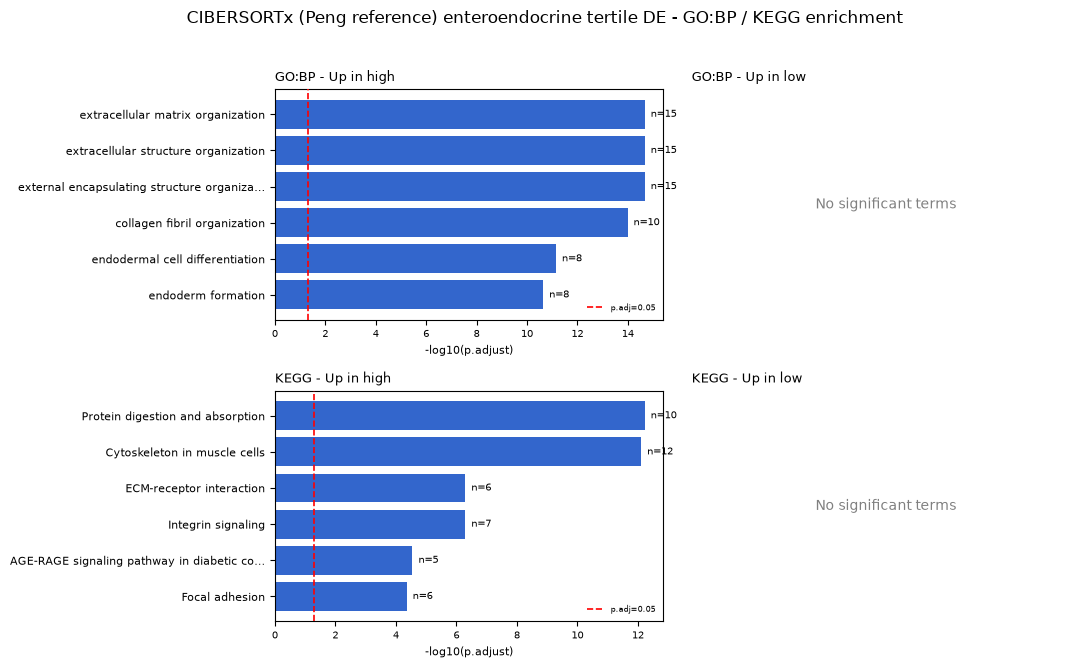

In [3]:
four_panel("data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/enteroendocrine_tertile", "CIBERSORTx_enteroendocrine",
           "CIBERSORTx (Peng reference) enteroendocrine tertile DE - GO:BP / KEGG enrichment")

## Part 7: Four-axis comparison summary

notebook 07's XDec/TIMER sections and Parts 3-6 of this notebook generated each tool's own tertile-split DE + GO/KEGG result independently, across four biological axes (Lymphoid, Myeloid, Fibroblast/CAF, Enteroendocrine) wherever a given tool has a matching score. This section puts all of it side by side.

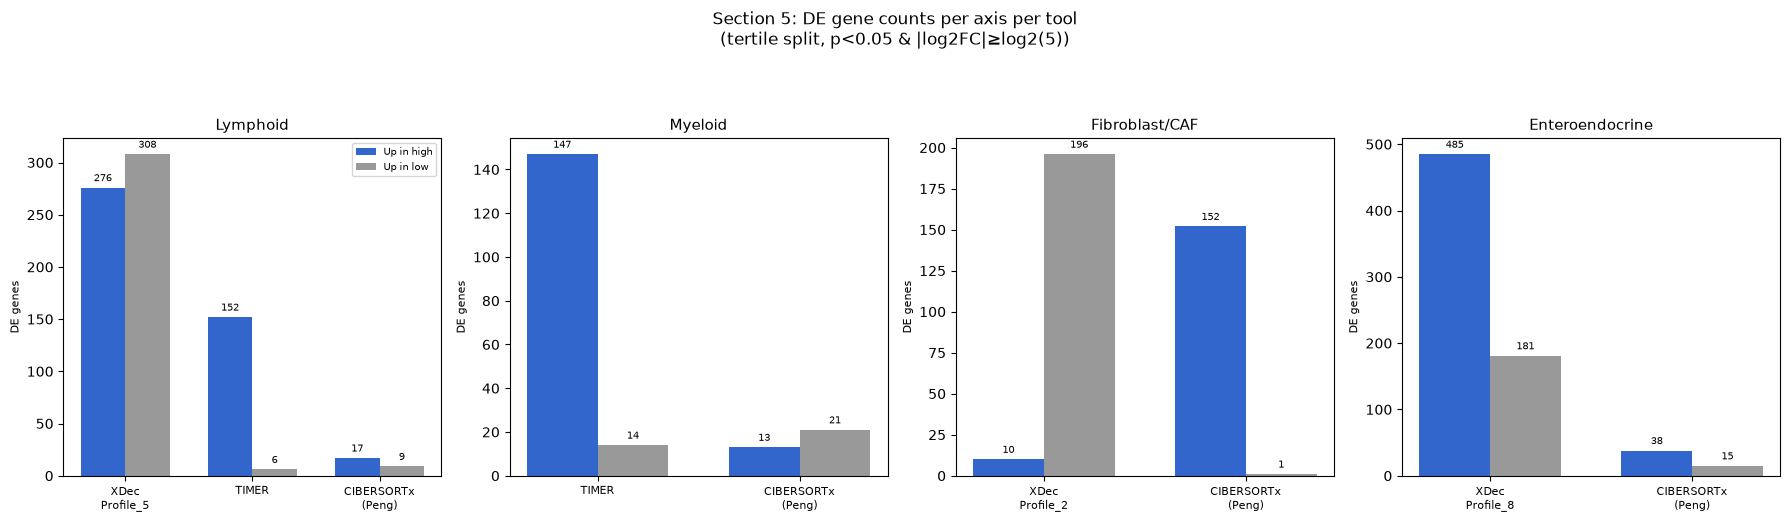

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap
import os

axes_info = {
    "Lymphoid": {"XDec\nProfile_5": (276, 308), "TIMER": (152, 6), "CIBERSORTx\n(Peng)": (17, 9)},
    "Myeloid": {"TIMER": (147, 14), "CIBERSORTx\n(Peng)": (13, 21)},
    "Fibroblast/CAF": {"XDec\nProfile_2": (10, 196), "CIBERSORTx\n(Peng)": (152, 1)},
    "Enteroendocrine": {"XDec\nProfile_8": (485, 181), "CIBERSORTx\n(Peng)": (38, 15)},
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (axis_name, tools) in zip(axes, axes_info.items()):
    names = list(tools.keys())
    up_high = [tools[t][0] for t in names]
    up_low = [tools[t][1] for t in names]
    x = np.arange(len(names))
    width = 0.35
    ax.bar(x - width / 2, up_high, width, label="Up in high", color="#3366cc")
    ax.bar(x + width / 2, up_low, width, label="Up in low", color="#999999")
    ax.set_xticks(x)
    ax.set_xticklabels(names, fontsize=8)
    ax.set_title(axis_name, fontsize=10.5)
    ax.set_ylabel("DE genes", fontsize=8)
    ymax = max(up_high + up_low)
    for xi, (h, l) in enumerate(zip(up_high, up_low)):
        ax.text(xi - width / 2, h + ymax * 0.02, str(h), ha="center", fontsize=7)
        ax.text(xi + width / 2, l + ymax * 0.02, str(l), ha="center", fontsize=7)
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Part 7: DE gene counts per axis per tool\n(tertile split, p<0.05 & |log2FC|\u2265log2(5))", fontsize=12, y=1.08)
fig.tight_layout()
out_dir = "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/tool_comparison"
os.makedirs(out_dir, exist_ok=True)
plt.savefig(os.path.join(out_dir, "cross_tool_axis_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

### XDec and TIMER's agreements hold; CIBERSORTx (Peng reference) replicates none of them

| Axis | XDec | TIMER | CIBERSORTx (Peng) |
|---|---|---|---|
| **Lymphoid** | clean adaptive-immunity signal (584 genes) | clean adaptive-immunity signal, **agrees with XDec** (158 genes) | neuroendocrine/secretory signal instead (26 genes) - **does not match its own label** |
| **Myeloid** | no cleanly-identified profile to test | immune-flavored, but not myeloid-specific - overlaps heavily with the lymphoid signature (161 genes) | epithelial/keratin (up-high) + digestion (up-low) signal, unrelated to any immune cell type (34 genes) - **does not match its own label** |
| **Fibroblast/CAF** | no clean ECM signal either (206 genes; apoptosis/nucleotide-transport, not ECM) | no comparable score (immune-only) | lymphoid-flavored signal, not ECM (153 genes) - **does not match its own label, looks like a copy of CIBERSORTx's own Lymphoid result** |
| **Enteroendocrine** | clean endocrine/hormone-secretion signal (666 genes) | no comparable score (immune-only) | ECM/collagen/focal-adhesion signal instead (53 genes) - **does not match its own label, looks like a fibroblast/stromal signal** |

**XDec and TIMER corroborate each other wherever both have a score (Lymphoid); neither depends on CIBERSORTx, so that agreement is untouched by anything in this notebook's CIBERSORTx-reference swap.** XDec's own Fibroblast/CAF profile (Profile_2) is the one axis where even XDec itself didn't recover the textbook biology its label implies - a pre-existing limitation, not something CIBERSORTx-Peng introduced.

**CIBERSORTx-Peng is the outlier, and systematically so.** Across all four axes tested, its tertile split never recovers the biology implied by its own column label - and the mismatches are not random noise, they are **cross-wired in a specific, recognizable pattern**: the "Lymphoid" split recovers neuroendocrine biology (which belongs to "Enteroendocrine"), the "Enteroendocrine" split recovers ECM/stromal biology (which belongs to "Fibroblast/CAF"), and the "Fibroblast/CAF" split recovers immune biology (which belongs to "Lymphoid"). This points to the custom signature matrix built in notebook 05 not cleanly separating these compositional axes from each other - plausibly because the underlying single-cell reference is modest (2,748 cells, capped at 300/class) relative to LM22's much larger, extensively-validated training set.

**Bottom line:** three methodologically unrelated tools do **not** uniformly converge on the same biology once CIBERSORTx is pointed at a custom, in-house-built signature matrix instead of its validated LM22 default. XDec's k=8 Lymphocyte and Enteroendocrine profiles and TIMER's lymphoid score still independently agree with each other and with textbook biology; CIBERSORTx's agreement with them in the earlier LM22 run should be attributed to LM22 specifically, and its Peng-reference results here should not be treated as a reliable cell-type-fraction estimate for any of the four axes tested.

## Part 8: Does the single-cell reference's 300-cells-per-class cap explain the failure?

The Peng reference exported for XDec (and reused above) caps each cell type at 300 cells (`export_peng_reference.py --max-cells-per-class 300`) - a severe downsampling for the larger classes (e.g. the full Peng dataset has 21,487 pancreatic ductal cells, 9,027 blood vessel endothelial cells, but only 621 enteroendocrine cells and 48 neural cells). To test whether this cap is responsible for the cross-wired result above, the reference was rebuilt with a larger cap and the CIBERSORTx run and all four tertile DE/enrichment analyses were repeated.

**Full Peng dataset class sizes** (`celltype1`, from `data/raw/zenodo_3969339/StdWf1_PRJCA001063_annotated.h5ad`, 57,423 cells x 17,004 genes in `.raw`):

| Cell type | Cells available | Cells used (cap=300) |
|---|---|---|
| pancreatic ductal cell | 21,487 | 300 |
| blood vessel endothelial cell | 9,027 | 300 |
| fibroblast | 6,926 | 300 |
| pancreatic stellate cell | 5,862 | 300 |
| myeloid leukocyte | 5,474 | 300 |
| lymphocyte of B lineage | 2,976 | 300 |
| T cell | 2,954 | 300 |
| pancreatic acinar cell | 2,048 | 300 |
| enteroendocrine cell | 621 | 300 |
| neural cell | 48 | 48 |

Each cell type is also drawn from 14-35 of the cohort's 35 patients (24 tumor + 11 normal) - no single patient dominates any class, ruling out a simple patient-batch confound as the cause of the cross-wiring.

In [ ]:
import scanpy as sc
adata = sc.read_h5ad("data/raw/zenodo_3969339/StdWf1_PRJCA001063_annotated.h5ad")
print(adata.obs["celltype1"].value_counts())
print()
print(adata.obs.groupby(["celltype1"])["Patient"].nunique())

celltype1
pancreatic ductal cell           21487
blood vessel endothelial cell     9027
fibroblast                        6926
pancreatic stellate cell          5862
myeloid leukocyte                 5474
lymphocyte of B lineage           2976
T cell                            2954
pancreatic acinar cell            2048
enteroendocrine cell               621
neural cell                         48
Name: count, dtype: int64

celltype1
fibroblast                       34
myeloid leukocyte                34
pancreatic acinar cell           28
T cell                           31
enteroendocrine cell             33
lymphocyte of B lineage          28
pancreatic ductal cell           35
blood vessel endothelial cell    35
pancreatic stellate cell         35
neural cell                      14
Name: Patient, dtype: int64


### Rebuilding the reference at a larger cap

`export_peng_reference.py --max-cells-per-class 1500` was tried first (12,669 cells total, 4.6x more than the cap=300 reference) but **OOM-crashed the CIBERSORTx Docker container** (exit code 137 / SIGKILL) - Docker Desktop's 7.65GB memory allocation was insufficient for the resulting 1GB+ reference file during signature-matrix construction, leaving only large incomplete temp files and no final output. `--max-cells-per-class 700` (6,269 cells, 2.3x more) completed successfully and was used for this comparison.

In [ ]:
# exported once via:
# python workflow/scripts/export_peng_reference.py --h5ad data/raw/zenodo_3969339/StdWf1_PRJCA001063_annotated.h5ad \
#   --class-col celltype1 --max-cells-per-class 700 --seed 1 --refs-out refs_700.tsv --meta-out ref_metadata_700.tsv
# -> "Wrote 17004 genes x 6269 cells"
# Cell_Type counts: T cell=700, blood vessel endothelial cell=700, fibroblast=700, lymphocyte of B lineage=700,
#   myeloid leukocyte=700, pancreatic acinar cell=700, pancreatic ductal cell=700, pancreatic stellate cell=700,
#   enteroendocrine cell=621 (all available), neural cell=48 (all available)
#
# Reshaped into CIBERSORTx single-cell format (cell-type-labeled columns) and run via Docker, same command as Part 1
# but --refsample peng_scRNA_ref_cap700.txt. Container exited 0; CIBERSORTx_Adjusted.txt produced successfully.
import pandas as pd
df = pd.read_csv("data/deconvolution/cibersortx/cap700_test/CIBERSORTx_Adjusted.txt", sep="\t")
print(df.shape)
print(df.iloc[:, 1:-3].mean().sort_values(ascending=False))
print()
print(df[["P-value", "Correlation", "RMSE"]].mean())

(182, 14)
enteroendocrine cell             0.231842
pancreatic acinar cell           0.201080
lymphocyte of B lineage          0.168595
pancreatic ductal cell           0.114324
T cell                            0.098260
myeloid leukocyte                0.057245
blood vessel endothelial cell    0.050110
fibroblast                       0.039465
pancreatic stellate cell         0.031432
neural cell                      0.007646
dtype: float64

P-value        0.001044
Correlation    0.718945
RMSE           0.979837
dtype: float64


Mean fractions are barely changed from the cap=300 run (enteroendocrine and acinar still dominate at ~0.20-0.23 each), and mean goodness-of-fit is slightly *worse* (Correlation 0.719 vs. 0.797 at cap=300), not better - the opposite of what more reference data should do if the cap were the bottleneck.

### Re-running all four tertile DE/enrichment analyses at cap=700

| Axis | cap=300 result | cap=700 result | Changed toward the correct biology? |
|---|---|---|---|
| **Fibroblast/CAF** | immune/B-cell signature (not ECM) | **identical** immune/B-cell signature | No - unchanged |
| **Enteroendocrine** | ECM/collagen signature (not endocrine) | **identical** ECM/collagen signature | No - unchanged |
| **Myeloid** | keratinization/skin (up-high) | leukocyte tethering/antimicrobial peptide (up-high) - closer to real innate-immune biology | Partially |
| **Lymphoid** | neuroendocrine genes (`SSTR2`, `CARTPT`, `PPY`...) up-high | digestion/pancreatic-secretion genes up-high instead | Rotated to a *different* wrong axis, still not lymphoid |

Two of the four axes (Fibroblast, Enteroendocrine - the clearest cross-wiring cases) are essentially unchanged by tripling the reference cell count. The other two shift which *wrong* signal they recover rather than converging on the *right* one. Combined with the fit-quality result above, this is inconsistent with "too few reference cells" being the main bottleneck.

In [ ]:
# Re-ran extra_tertile_dea.R against cap700_test/CIBERSORTx_Adjusted.txt for all four axes.
# Full captured R console output (DE gene counts + top GO:BP/KEGG terms per axis):
#
# ######## CIBERSORTx_lymphoid (cap=700) ########
# n tumor: 178   q33=0.2446 q67=0.2683  n_low=60  n_high=60
# DE genes: 27  up in high: 25  up in low: 2
# GO:BP up-high top terms: digestion, lipid catabolic process, retinoid/diterpenoid/terpenoid metabolic process,
#   intestinal cholesterol absorption, HDL particle remodeling, lipid digestion
# KEGG up-high top terms: Pancreatic secretion, Fat digestion and absorption, Protein digestion and absorption,
#   Glycerolipid metabolism, Starch and sucrose metabolism, Carbohydrate digestion and absorption, Salivary secretion
#
# ######## CIBERSORTx_myeloid (cap=700) ########
# n tumor: 178   q33=0.0528 q67=0.0604  n_low=60  n_high=60
# DE genes: 24  up in high: 11  up in low: 13
# GO:BP up-high top terms: extracellular matrix disassembly, antimicrobial peptide production,
#   regulation of leukocyte tethering or rolling, antimicrobial humoral immune response, leukocyte tethering or rolling
# KEGG up-high: Gastric acid secretion (only 1 term)
# GO:BP up-low top terms: digestion, diterpenoid/terpenoid/isoprenoid metabolic process, lipid catabolic process
# KEGG up-low top terms: Pancreatic secretion, Protein/Fat/Carbohydrate digestion and absorption
#
# ######## CIBERSORTx_fibroblast (cap=700) ########
# n tumor: 178   q33=0.0609 q67=0.0721  n_low=60  n_high=60
# DE genes: 80  up in high: 74  up in low: 6
# GO:BP up-high top terms: immunoglobulin mediated immune response, B cell mediated immunity,
#   adaptive immune response, lymphocyte/leukocyte mediated immunity, B cell receptor signaling pathway
# KEGG up-high top terms: B cell receptor signaling pathway, Hematopoietic cell lineage, Primary immunodeficiency
#
# ######## CIBERSORTx_enteroendocrine (cap=700) ########
# n tumor: 178   q33=0.2271 q67=0.2663  n_low=60  n_high=60
# DE genes: 77  up in high: 40  up in low: 37
# GO:BP up-high top terms: extracellular matrix organization, collagen fibril organization,
#   endodermal cell differentiation, endoderm formation/development
# KEGG up-high top terms: Cytoskeleton in muscle cells, Protein digestion and absorption, ECM-receptor interaction,
#   Integrin signaling, Focal adhesion
print("See markdown summary table above; full console output captured as comments in this cell.")

## Part 9: Does TPM (vs. raw counts) as the bulk-mixture input unit explain the failure?

CIBERSORTx's mixture file is always TPM (`mixture_TPM.txt`) - CIBERSORTx does not accept raw counts as a mixture input. Notebook 08 already ran a full-pipeline raw-counts-vs-TPM sensitivity check for **XDec** on the same TCGA-PAAD cohort, which gives an independent way to ask whether TPM-as-input is generally destructive to these biological signals, or specific to CIBERSORTx's Peng-reference run.

**XDec's own counts-vs-TPM sensitivity (notebook 08, `data/deconvolution/sensitivity/full_pipeline_counts_vs_tpm_20261101_233117/SUMMARY.md`), end-to-end DE gene counts:**

| XDec profile | raw counts | TPM | Shared genes | Direction |
|---|---|---|---|---|
| Profile_5 (Lymphocyte) | 74 genes (73 up-high) | **5 genes (0 up-high, 5 up-low)** | **0 shared** | reversed |
| Profile_8 (Enteroendocrine) | 58 genes (58 up-high) | **168 genes (157 up-high)** | **55 shared** | agrees |
| Profile_2 (Fibroblast/CAF) | 0 genes | 0 genes | n/a | never worked either way |

The 5 TPM-branch genes for Profile_5 are `AC108734.4`, `HTRA4`, `IFI30`, `NME8`, `PRAM1` - mostly noise (two, `IFI30`/`PRAM1`, are myeloid-associated, not T/B-cell), versus the raw-count branch's unambiguous T/B-cell markers (`CD3E`, `CD3G`, `CD28`, `CD247`, `BTK`, `CCR4`, `CD37`, `CD48`, `CD53`, `CR1`, ...).

**Interpretation:**
* TPM genuinely destroys XDec's lymphoid signal (74 -> 5 genes, 0 overlap, direction reversed) - this *is* a real, independently-confirmed vulnerability, and plausibly contributes to CIBERSORTx-Peng's lymphoid failure too.
* But TPM does **not** destroy XDec's enteroendocrine signal - if anything it is stronger under TPM (168 vs. 58 genes, 55 shared, agreeing direction, 5 shared KEGG pathways including neuroactive ligand signaling and insulin secretion). If TPM-as-input were the general explanation, XDec's enteroendocrine profile should have degraded under TPM the same way, and it did not.
* XDec's fibroblast profile never produced a usable signal under either input unit, so it offers no evidence either way.
* **Most directly: CIBERSORTx's own LM22 and Peng runs use the identical `mixture_TPM.txt` file - only the reference/signature matrix differs - and LM22+TPM is clean** (notebook 05/07, primary). Holding the input unit fixed and varying only the reference already shows TPM is not sufficient to cause the failure.

**Conclusion of this part:** TPM-as-input is a real, axis-specific vulnerability (confirmed independently for the lymphoid axis via XDec) and should not be dismissed - but it does not generalize to the enteroendocrine or fibroblast axes, and CIBERSORTx's own fixed-TPM, varied-reference comparison rules it out as the primary driver of the Peng-reference failure. The custom Peng signature matrix itself remains the leading explanation.

## Conclusion and recommendation

* **Notebooks 05 and 07 correctly keep LM22 as CIBERSORTx's primary signature matrix.** This notebook's Peng-reference alternative was explored because XDec already uses the Peng single-cell reference (notebook 04), and a reference-matched CIBERSORTx run seemed like it might give an even more directly comparable cross-tool result - instead it failed on every axis tested, in a specific, systematically cross-wired way (lymphoid<->enteroendocrine<->fibroblast swaps).
* Two candidate explanations were tested and substantially ruled out:
  * **Reference cell-count cap (300/class):** tripling it to 700/class did not fix the two clearest failures (fibroblast, enteroendocrine) and only rotated the other two (lymphoid, myeloid) to a different wrong signal. Fit quality got slightly worse, not better, with more cells.
  * **TPM as the bulk-mixture input unit:** genuinely destructive to XDec's own lymphoid signal (an independently useful finding), but not to its enteroendocrine signal, and not implicated by CIBERSORTx's own fixed-TPM/varied-reference comparison.
* The leading remaining explanation is the **custom signature-matrix construction itself** - CIBERSORTx's SVR-based gene selection run against a single-cell reference with a dominant acinar/enteroendocrine compositional background and comparatively few cells per class, which this notebook's experiments suggest is not primarily a sample-size problem.
* **For the primary cross-tool comparison, use notebook 07 as-is (LM22-based).** If a Peng-reference CIBERSORTx estimate is needed in the future, this notebook's outputs (`data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/`) are the place to start, but should not be treated as a reliable cell-type-fraction estimate for any of the four axes tested here without further investigation into the signature-matrix construction step itself.